Objectives: 

1. Implement conditional logic to route the flow of data to different nodes. 
2. Use START and END nodes to manage entry and exit points explicitly. 
3. Design multiple nodes to perform different operations, like addition and subtraction. 
4. Create a router node to handle decision making and control graph flow. 

Main goal: How to use add_conditional_edge().

In [2]:
from typing import List , TypedDict
from langgraph.graph import StateGraph , START , END

In [3]:
class AgentState(TypedDict):
    number1 : int
    number2 : int
    operator : str
    result : int

In [ ]:
def add_operation(state : AgentState) -> AgentState :
    """This node adds two numbers and stores the result in the result slot"""
    state['result'] = state['number1'] + state['number2']
    return state

In [5]:
def subtract_operation(state : AgentState) -> AgentState :
    """This node subtracts two numbers and stores the result in the result slot"""
    state['result'] = state['number1'] - state['number2']
    return state

In [7]:
def decide_next_node(state : AgentState) -> AgentState :
    """This node makes a decision which operation to perform"""
    if state['operator']  == '+':
        return "addition"
    elif state['operator']  == '-':
        return "subtraction"
   

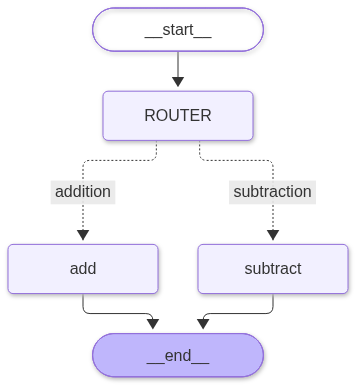

In [11]:
graph = StateGraph(AgentState)

graph.add_node("ROUTER", lambda state : state)
graph.add_node("add", add_operation)
graph.add_node("subtract", subtract_operation)


graph.add_edge(START,"ROUTER")
graph.add_conditional_edges("ROUTER",
            decide_next_node,
            {
                "addition":"add",
                "subtraction":"subtract"
            })

graph.add_edge("add",END)
graph.add_edge("subtract",END)

app = graph.compile()
app


In [14]:
result =app.invoke({"number1":1,"number2":2,"operator":"+"})

In [15]:
result

{'number1': 1, 'number2': 2, 'operator': '+', 'result': 3}